# Day 9 Exercises: PINNs for Differential Equations

Student version with gaps.

## Context

This lab builds physics-informed neural networks (PINNs) from the residuals in the Day 9 lecture. You will first implement a standard ODE PINN with a weak initial-condition loss, then use automatic differentiation for a 2D Poisson problem, a Deep Ritz energy loss, and a one-time/one-space heat equation. The final exercise replaces soft condition losses by hard constraint ansatz functions.

The examples are deliberately small. The goal is to understand residual construction, energy-based losses, diagnostics, and constraint enforcement, not to produce a state-of-the-art PDE solver.

> #### Instructions
>
> Run the setup cells first. Then complete each exercise-local implementation cell before running the corresponding diagnostics.


## Learning Goals

A PINN replaces a classical discretization error equation by a differentiable neural-network residual evaluated at collocation points. A Deep Ritz method instead minimizes an energy functional. This notebook keeps the models small so that the residuals, loss components, and condition errors are visible.

By the end of the lab you should be able to:

- implement ODE and PDE residuals with JAX input derivatives;
- train a standard PINN with soft initial or boundary losses;
- implement a Deep Ritz energy loss for a Poisson problem;
- interpret loss components, validation residuals, and condition errors;
- run and interpret a compact hyperparameter sweep;
- implement hard initial and boundary constraints through ansatz functions;
- compare residual-based and energy-based training diagnostics.


## Shared PINN Workflow

### Notebook convention
Blocks labelled **Instructions** tell you what to do. Blocks labelled **Open questions** are the questions to answer after running the diagnostics.

### Structure
Most exercises use the same modelling pattern: choose collocation points, define a trial function, evaluate a strong-form residual with automatic differentiation, combine residual and condition losses, train with Adam, and inspect validation diagnostics. The Deep Ritz run keeps the same neural trial-function family and a boundary penalty, but replaces the squared residual by an energy density.

### What stays fixed?
The tanh MLP implementation, Adam optimizer, collocation constructors, exact solutions, diagnostic tables, and plotting helpers are shared.

### What changes between exercises?
Exercise 1 changes the ODE hyperparameters. Exercise 2 changes the differential equation, the input dimension, and the loss formulation. Exercise 3 changes the trial function so that selected conditions are satisfied exactly.


## Setup

The shared network, exact-solution, collocation, optimizer, evaluation, and plotting helpers live next to this notebook in `day9_helpers.py`. The notebook imports those provided pieces here; the implementation tasks remain inside the exercise sections below.

You may open `day9_helpers.py` if you want to inspect the provided infrastructure. This is optional: the core lab does not require reading or editing the helper file.

> #### Instructions
>
> Run this cell before starting the exercises. You do not need to edit the helper module during the core lab.


In [1]:
from pathlib import Path
import sys

# Make the local helper module importable when running from the day folder,
# the notebooks folder, the quarto folder, or the course root.
for helper_dir in [
    Path.cwd(),
    Path.cwd() / "day9",
    Path.cwd() / "notebooks" / "day9",
    Path.cwd() / "quarto" / "notebooks" / "day9",
]:
    if (helper_dir / "day9_helpers.py").exists():
        sys.path.insert(0, str(helper_dir))
        break

from day9_helpers import *  # Provided teaching infrastructure for this lab.


## Data and Collocation Inspection

Before training, inspect the collocation and condition points. PINNs only see the residual at sampled points, so the point sets are part of the numerical method.

> #### Instructions
>
> Run the cell and check where the residual, initial-condition, and boundary-condition losses will be evaluated.


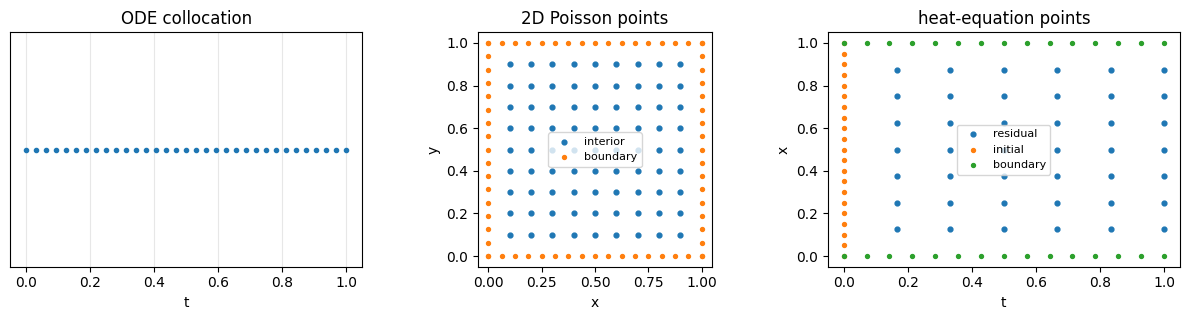

In [2]:
ode_points = make_ode_collocation(33)
poisson_interior = make_square_interior_grid(9)
poisson_boundary = make_square_boundary_points(17)
heat_points = make_heat_points()

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.3))
axes[0].plot(np.asarray(ode_points).ravel(), np.zeros(len(ode_points)), "o", markersize=3)
axes[0].set_title("ODE collocation")
axes[0].set_xlabel("t")
axes[0].set_yticks([])
axes[0].grid(True, alpha=0.3)

axes[1].scatter(np.asarray(poisson_interior[:, 0]), np.asarray(poisson_interior[:, 1]), s=12, label="interior")
axes[1].scatter(np.asarray(poisson_boundary[:, 0]), np.asarray(poisson_boundary[:, 1]), s=8, label="boundary")
axes[1].set_title("2D Poisson points")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_aspect("equal")
axes[1].legend(fontsize=8)

axes[2].scatter(np.asarray(heat_points["interior"][:, 0]), np.asarray(heat_points["interior"][:, 1]), s=12, label="residual")
axes[2].scatter(np.asarray(heat_points["initial"][:, 0]), np.asarray(heat_points["initial"][:, 1]), s=8, label="initial")
axes[2].scatter(np.asarray(heat_points["boundary"][:, 0]), np.asarray(heat_points["boundary"][:, 1]), s=8, label="boundary")
axes[2].set_title("heat-equation points")
axes[2].set_xlabel("t")
axes[2].set_ylabel("x")
axes[2].legend(fontsize=8)
fig.tight_layout()

## Exercise 1: Standard PINN for the Lecture ODE

The lecture ODE is

$$
y'(t)=\kappa\pi\cos(\kappa\pi t), \qquad y(0)=0, \qquad y(t)=\sin(\kappa\pi t).
$$

A standard PINN uses a neural trial function `y_theta(t)` and minimizes a residual loss plus a weak/soft initial-condition loss.

> #### Instructions
>
> 1. Implement `ode_residual` and `soft_initial_condition_loss` in the Exercise 1 implementation cell.
> 2. Train the baseline `kappa=1` PINN.
> 3. Complete `make_ode_hyperparameter_experiments` in the same implementation cell and run the compact `kappa=4` sweep.
> 4. Compare the table, loss histories, fitted curves, residuals, and initial-condition errors.


In [3]:
# Exercise 1 implementation tasks

def ode_residual(params, t_points, kappa, trial_fn=ode_soft_trial):
    """Return r_theta(t) = y_theta'(t) - kappa*pi*cos(kappa*pi*t)."""
    def y_scalar(t_scalar):
        return trial_fn(params, jnp.array([t_scalar]))

    dy_dt = jax.grad(y_scalar)

    def residual_at(t_scalar):
        return dy_dt(t_scalar) - kappa * jnp.pi * jnp.cos(kappa * jnp.pi * t_scalar)

    residual = jax.vmap(residual_at)(t_points.ravel())
    return residual.reshape(-1, 1)


def soft_initial_condition_loss(params, trial_fn=ode_soft_trial, y0=0.0):
    """Return |y_theta(0) - y0|^2 for a scalar ODE trial function."""
    y_at_zero = trial_fn(params, jnp.array([0.0]))
    return jnp.square(y_at_zero - y0)


def make_ode_hyperparameter_experiments():
    """Return a small list of ODE PINN hyperparameter configurations."""
    base = {
        "hidden_layers": (24, 24),
        "num_collocation": 33,
        "steps": 650,
        "kappa": 4.0,
        "seed": 2,
    }
    return [
        {**base, "name": "wIC=1, lr=1e-3", "ic_weight": 1.0, "learning_rate": 1.0e-3},
        {**base, "name": "wIC=10, lr=1e-3", "ic_weight": 10.0, "learning_rate": 1.0e-3},
        {**base, "name": "wIC=50, lr=1e-3", "ic_weight": 50.0, "learning_rate": 1.0e-3},
        {**base, "name": "wIC=10, lr=3e-3", "ic_weight": 10.0, "learning_rate": 3.0e-3},
    ]

> #### Instructions
>
> Run the Exercise 1 shape checks and training diagnostics after completing the implementation tasks above.


Baseline ODE PINN
name                             val L2   val residual    condition   last total
--------------------------------------------------------------------------------
ODE baseline kappa=1          6.462e-03      6.817e-02    1.982e-04    5.122e-03
Hyperparameter sweep for kappa=4
name                             val L2   val residual    condition   last total
--------------------------------------------------------------------------------
wIC=1, lr=1e-3                8.032e-03      1.381e-01    1.152e-03    2.185e-02
wIC=10, lr=1e-3               8.027e-03      1.709e-01    8.173e-05    3.225e-02
wIC=50, lr=1e-3               1.734e-02      5.170e-01    3.296e-05    2.643e-01
wIC=10, lr=3e-3               4.855e-03      1.375e-01    5.964e-03    1.894e-02
Best validation solution error: wIC=10, lr=3e-3


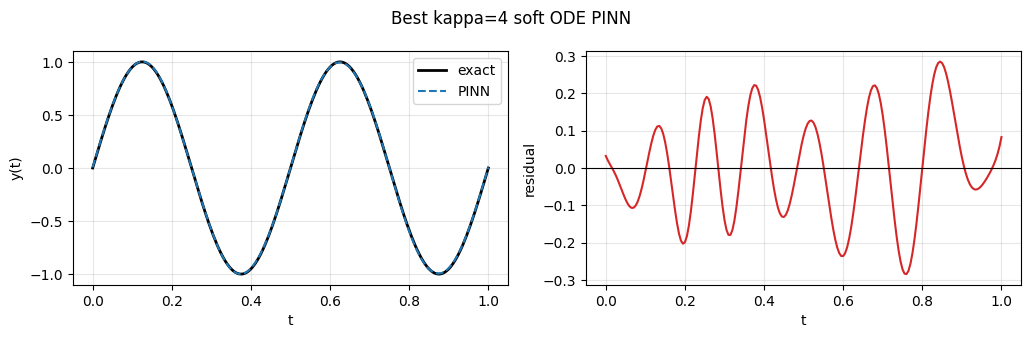

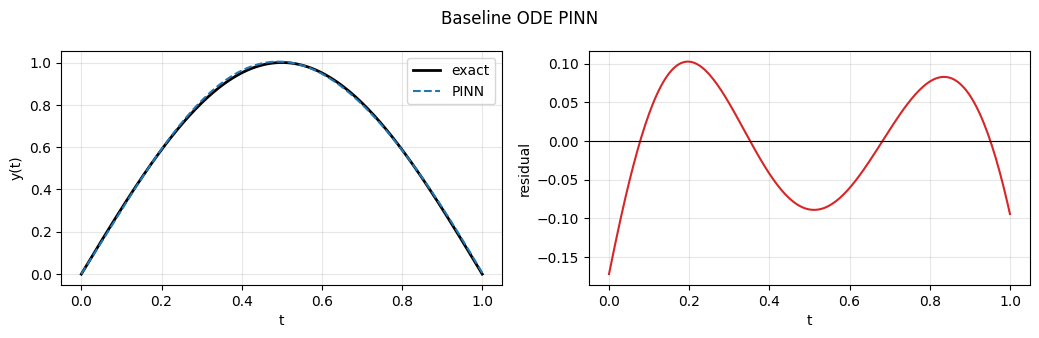

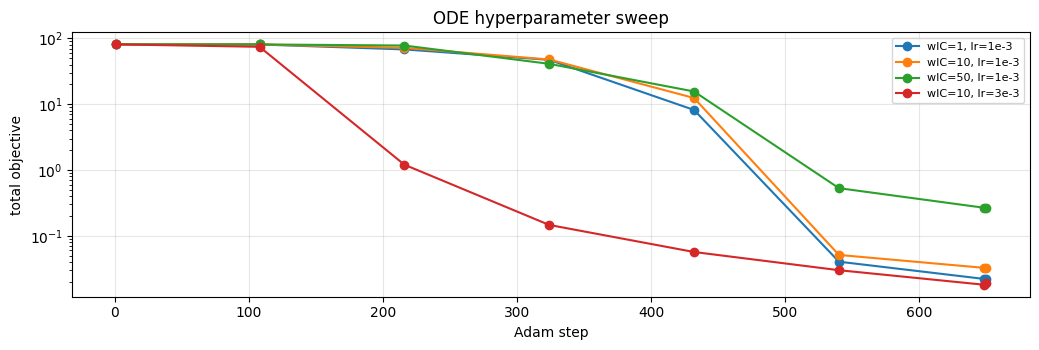

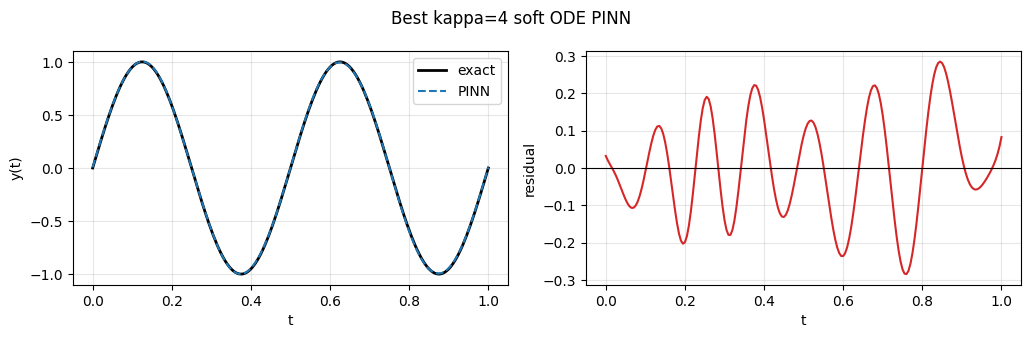

In [4]:
# Small shape checks before launching the training runs.
_test_ode_params = init_tanh_mlp(random.PRNGKey(0), 1, (8,))
_test_ode_points = make_ode_collocation(5)
assert ode_residual(_test_ode_params, _test_ode_points, kappa=1.0).shape == (5, 1)
assert jnp.ndim(soft_initial_condition_loss(_test_ode_params)) == 0

ode_baseline_config = {
    "name": "ODE baseline kappa=1",
    "seed": 1,
    "hidden_layers": (24, 24),
    "num_collocation": 33,
    "steps": 650,
    "learning_rate": 1.0e-3,
    "ic_weight": 10.0,
    "kappa": 1.0,
}

ode_baseline = run_ode_experiment(
    ode_baseline_config,
    residual_fn=ode_residual,
    ic_loss_fn=soft_initial_condition_loss,
)
print_result_table([ode_baseline], title="Baseline ODE PINN")
plot_ode_fit_and_residual(ode_baseline, ode_residual, ode_soft_trial, title="Baseline ODE PINN")

ode_sweep_configs = make_ode_hyperparameter_experiments()
ode_sweep_results = [
    run_ode_experiment(config, ode_residual, soft_initial_condition_loss)
    for config in ode_sweep_configs
]
print_result_table(ode_sweep_results, title="Hyperparameter sweep for kappa=4")
plot_loss_histories(ode_sweep_results, title="ODE hyperparameter sweep")

best_ode_result = min(ode_sweep_results, key=lambda result: result["validation_l2"])
print(f"Best validation solution error: {best_ode_result['name']}")
plot_ode_fit_and_residual(best_ode_result, ode_residual, ode_soft_trial, title="Best kappa=4 soft ODE PINN")

> #### Further testing
>
> If time permits, rerun the sweep after changing only one of `ic_weight`, `learning_rate`, or `num_collocation`.
>
> #### Open questions
>
> 1. Which hyperparameter change is most visible in the validation diagnostics?
> 2. Does the smallest training loss also give the best validation behavior?
> 3. How does the initial-condition weight affect the curve near `t=0`?


## Exercise 2: 2D Poisson PINN and Deep Ritz Loss

Part A uses the strong form of the 2D Poisson problem on the unit square,

$$
-\Delta u=f, \qquad u|_{\partial\Omega}=0.
$$

Part B uses the corresponding Deep Ritz energy

$$
\mathcal E(u)=\int_\Omega \frac12 |\nabla u|^2-fu\,dx,
$$

together with a soft boundary penalty. Part C keeps the one-time/one-space heat equation as a short second-derivative example.

> #### Instructions
>
> 1. Implement `poisson_2d_residual` and train the soft-boundary 2D Poisson PINN.
> 2. Implement `poisson_deep_ritz_energy_density` and train the Deep Ritz variant.
> 3. Implement `heat_equation_residual` and train the soft initial/boundary heat-equation PINN.
> 4. Inspect the validation tables and plots.

For the derivative bookkeeping, use a scalar trial function of one point: `jax.grad` gives the input gradient and `jax.hessian` gives the second derivatives.


In [5]:
# Exercise 2 implementation tasks

def poisson_2d_residual(params, xy_points, trial_fn=poisson_soft_trial):
    """Return -Delta u_theta(x,y) - 2*pi^2*sin(pi*x)*sin(pi*y)."""
    def u_scalar(point):
        return trial_fn(params, point)

    hessian_fn = jax.hessian(u_scalar)

    def residual_at(point):
        hessian = hessian_fn(point)
        laplacian = hessian[0, 0] + hessian[1, 1]
        f = 2.0 * jnp.pi**2 * jnp.sin(jnp.pi * point[0]) * jnp.sin(jnp.pi * point[1])
        return -laplacian - f

    residual = jax.vmap(residual_at)(xy_points)
    return residual.reshape(-1, 1)


def poisson_deep_ritz_energy_density(params, xy_points, trial_fn=poisson_soft_trial):
    """Return 1/2 |grad u_theta|^2 - f u_theta for the Poisson problem."""
    def u_scalar(point):
        return trial_fn(params, point)

    grad_fn = jax.grad(u_scalar)

    def density_at(point):
        grad_u = grad_fn(point)
        u_value = u_scalar(point)
        f = 2.0 * jnp.pi**2 * jnp.sin(jnp.pi * point[0]) * jnp.sin(jnp.pi * point[1])
        return 0.5 * jnp.dot(grad_u, grad_u) - f * u_value

    density = jax.vmap(density_at)(xy_points)
    return density.reshape(-1, 1)


def heat_equation_residual(params, tx_points, nu, trial_fn=heat_soft_trial):
    """Return u_t(t,x) - nu*u_xx(t,x)."""
    def u_scalar(point):
        return trial_fn(params, point)

    grad_fn = jax.grad(u_scalar)
    hessian_fn = jax.hessian(u_scalar)

    def residual_at(point):
        u_t = grad_fn(point)[0]
        u_xx = hessian_fn(point)[1, 1]
        return u_t - nu * u_xx

    residual = jax.vmap(residual_at)(tx_points)
    return residual.reshape(-1, 1)

> #### Instructions
>
> Run the Exercise 2 shape checks and PDE diagnostics after completing the implementation tasks above.


2D Poisson strong-form PINN
name                             val L2   val residual    condition   last total
--------------------------------------------------------------------------------
Poisson strong form           1.211e-02      5.864e-01    2.259e-02    1.431e-01
2D Poisson: strong form versus Deep Ritz
name                             val L2   val residual    condition   last total
--------------------------------------------------------------------------------
Poisson strong form           1.211e-02      5.864e-01    2.259e-02    1.431e-01
Poisson Deep Ritz             5.415e-02      5.872e+00    1.722e-02   -3.031e+00
Heat-equation PINN
name                             val L2   val residual    condition   last total
--------------------------------------------------------------------------------
heat soft IC/BC               2.682e-02      2.624e-01    4.398e-02    9.044e-02


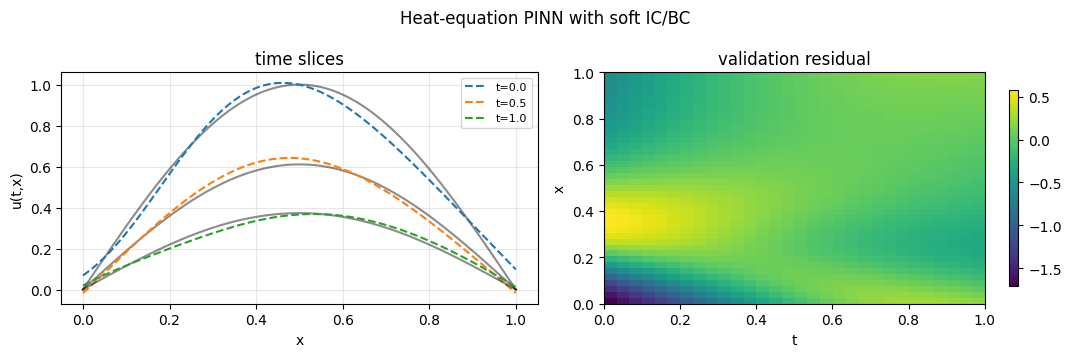

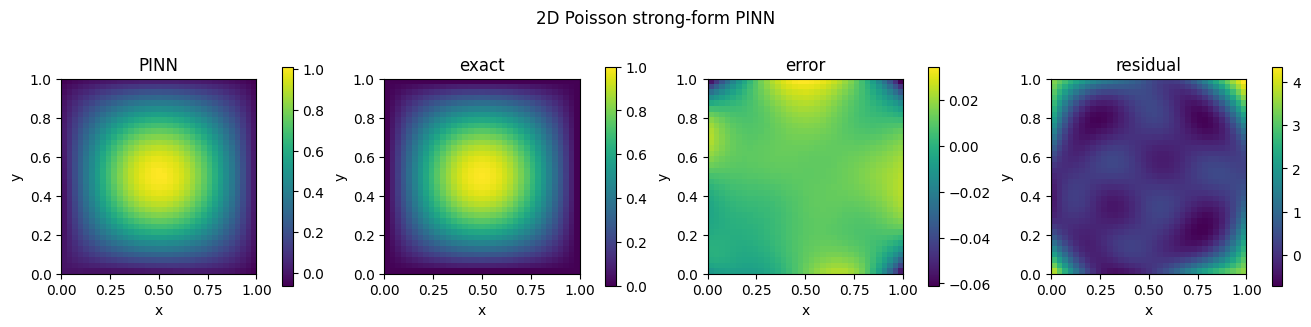

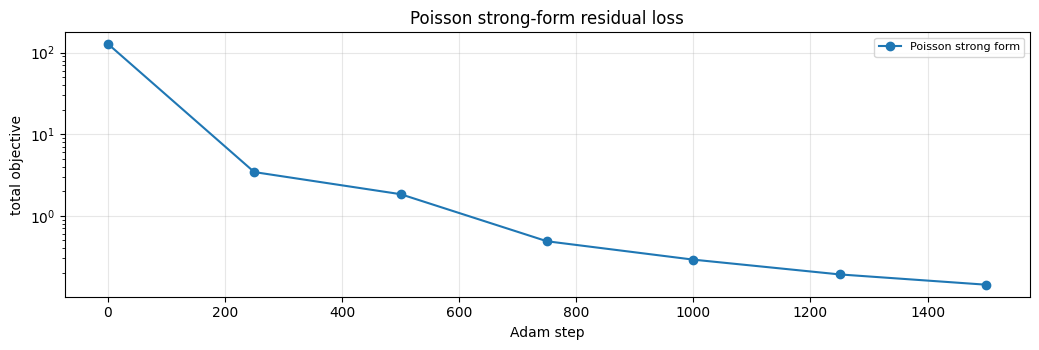

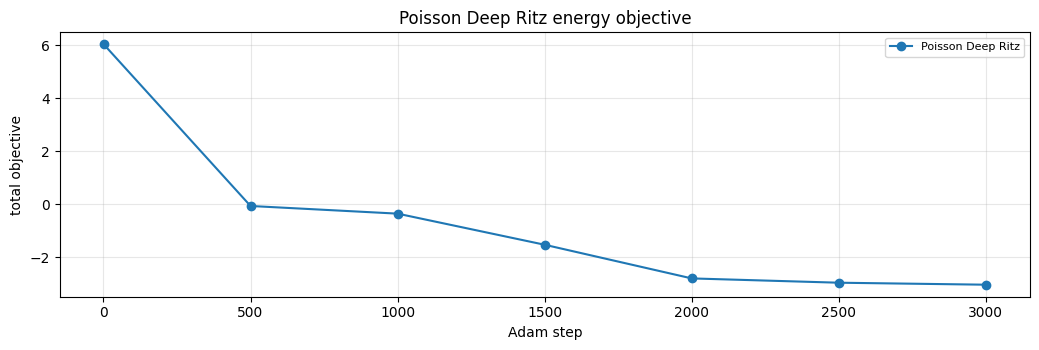

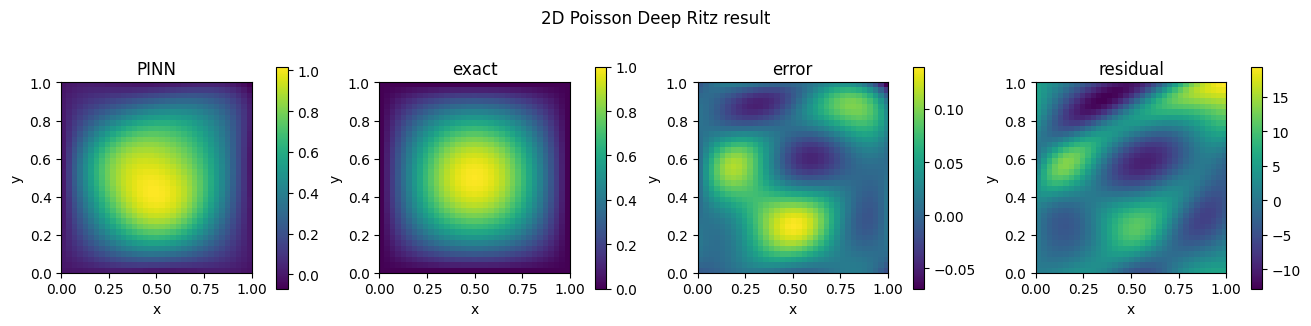

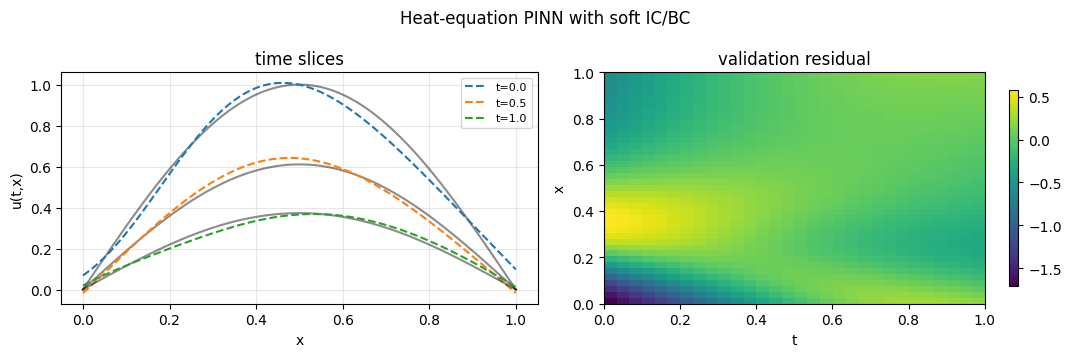

In [6]:
# Small shape checks before launching the PDE training runs.
_test_poisson_params = init_tanh_mlp(random.PRNGKey(0), 2, (8,))
_test_xy = make_square_interior_grid(2)
assert poisson_2d_residual(_test_poisson_params, _test_xy).shape == (_test_xy.shape[0], 1)
assert poisson_deep_ritz_energy_density(_test_poisson_params, _test_xy).shape == (_test_xy.shape[0], 1)
_test_heat_params = init_tanh_mlp(random.PRNGKey(1), 2, (8,))
_test_tx = make_heat_points(3, 4, 5, 5)["interior"]
assert heat_equation_residual(_test_heat_params, _test_tx, nu=0.1).shape == (_test_tx.shape[0], 1)

poisson_soft_config = {
    "name": "Poisson strong form",
    "seed": 21,
    "hidden_layers": (32, 32),
    "num_interior_axis": 9,
    "num_boundary_edge": 17,
    "steps": 1500,
    "learning_rate": 1.0e-3,
    "bc_weight": 50.0,
}
poisson_soft_result = run_poisson_soft_experiment(poisson_soft_config, poisson_2d_residual)
print_result_table([poisson_soft_result], title="2D Poisson strong-form PINN")
plot_poisson_fields(poisson_soft_result, poisson_2d_residual, poisson_soft_trial, title="2D Poisson strong-form PINN")

poisson_ritz_config = {
    "name": "Poisson Deep Ritz",
    "seed": 23,
    "hidden_layers": (48, 48),
    "num_interior_axis": 15,
    "num_boundary_edge": 25,
    "steps": 3000,
    "learning_rate": 1.0e-3,
    "bc_weight": 600.0,
}
poisson_ritz_result = run_poisson_deep_ritz_experiment(
    poisson_ritz_config,
    poisson_deep_ritz_energy_density,
    poisson_2d_residual,
)
print_result_table([poisson_soft_result, poisson_ritz_result], title="2D Poisson: strong form versus Deep Ritz")
plot_loss_histories([poisson_soft_result], title="Poisson strong-form residual loss")
plot_loss_histories([poisson_ritz_result], title="Poisson Deep Ritz energy objective")
plot_poisson_fields(poisson_ritz_result, poisson_2d_residual, poisson_soft_trial, title="2D Poisson Deep Ritz result")

heat_soft_config = {
    "name": "heat soft IC/BC",
    "seed": 22,
    "hidden_layers": (24, 24),
    "num_t_axis": 7,
    "num_x_axis": 9,
    "num_ic": 21,
    "num_bc": 15,
    "steps": 650,
    "learning_rate": 1.0e-3,
    "ic_weight": 20.0,
    "bc_weight": 20.0,
    "nu": 0.1,
}
heat_soft_result = run_heat_soft_experiment(heat_soft_config, heat_equation_residual)
print_result_table([heat_soft_result], title="Heat-equation PINN")
plot_heat_slices(heat_soft_result, heat_equation_residual, heat_soft_trial, title="Heat-equation PINN with soft IC/BC")


> #### Further testing
>
> If time permits, change only one collocation-grid size or loss weight in one of the Poisson runs.
>
> #### Open questions
>
> 1. Which Poisson formulation gives the smaller validation solution error?
> 2. Does the Deep Ritz objective tell the same story as the validation residual?
> 3. Do the boundary or initial-condition errors tell the same story as the solution error?


## Exercise 3: Hard Boundary and Initial Constraints

A hard constraint changes the trial function. Instead of adding every condition to the loss, the neural network is wrapped in an ansatz that satisfies selected conditions exactly.

For example,

$$
y_\theta(t)=y_0+t g_\theta(t)
$$

satisfies `y_theta(0)=y0` for every parameter vector.

> #### Instructions
>
> 1. Implement `hard_ode_ansatz`, `hard_poisson_2d_ansatz`, and `hard_heat_ansatz`.
> 2. Train hard-constrained versions of the ODE, Poisson, and heat examples.
> 3. Compare the condition errors, residuals, validation solution errors, and loss histories with the soft versions.


In [7]:
# Exercise 3 implementation tasks

def hard_ode_ansatz(params, point, y0=0.0):
    """Hard initial-condition ansatz y_theta(t) = y0 + t*g_theta(t)."""
    t = point[0]
    g = mlp_scalar(params, point)
    return y0 + t * g


def hard_poisson_2d_ansatz(params, point):
    """Hard homogeneous Dirichlet ansatz on the unit square."""
    x, y = point[0], point[1]
    boundary_factor = x * (1.0 - x) * y * (1.0 - y)
    g = mlp_scalar(params, point)
    return boundary_factor * g


def hard_heat_ansatz(params, point, nu=0.1):
    """Hard IC/BC ansatz for the heat equation."""
    t, x = point[0], point[1]
    initial_profile = jnp.exp(-nu * jnp.pi**2 * t) * jnp.sin(jnp.pi * x)
    boundary_factor = t * x * (1.0 - x)
    g = mlp_scalar(params, point)
    return initial_profile + boundary_factor * g

> #### Instructions
>
> Run the Exercise 3 shape checks and hard-constraint diagnostics after completing the implementation tasks above.


Matched soft versus hard ODE condition enforcement
name                             val L2   val residual    condition   last total
--------------------------------------------------------------------------------
wIC=10, lr=1e-3               8.027e-03      1.709e-01    8.173e-05    3.225e-02
ODE hard IC                   5.451e-02      8.973e-01    0.000e+00    8.641e-01
Poisson soft, Deep Ritz, and hard BCs
name                             val L2   val residual    condition   last total
--------------------------------------------------------------------------------
Poisson strong form           1.211e-02      5.864e-01    2.259e-02    1.431e-01
Poisson Deep Ritz             5.415e-02      5.872e+00    1.722e-02   -3.031e+00
2D Poisson hard BC            3.117e-02      2.431e+00    0.000e+00    4.747e+00
Soft versus hard heat-equation conditions
name                             val L2   val residual    condition   last total
-----------------------------------------------------------

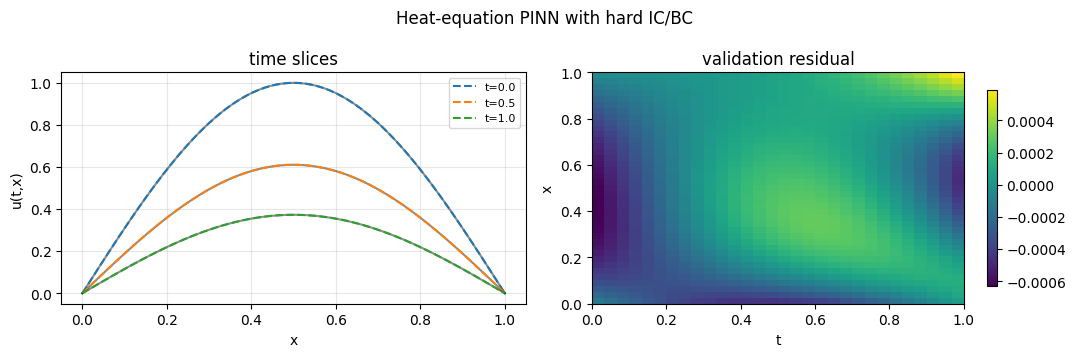

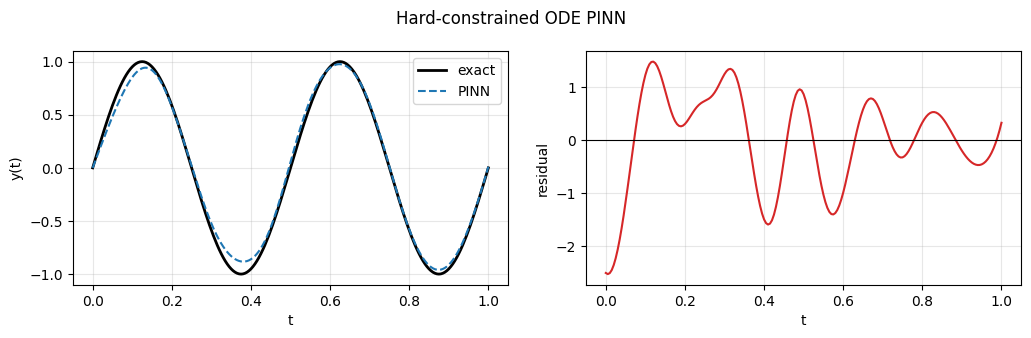

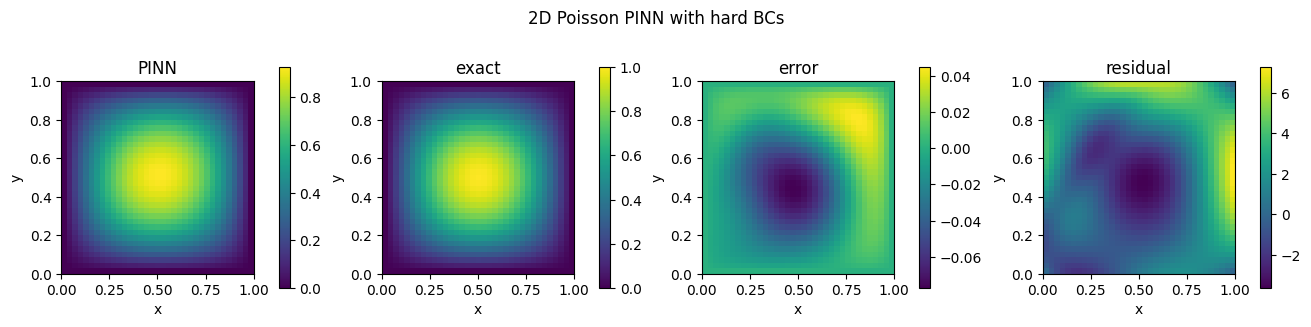

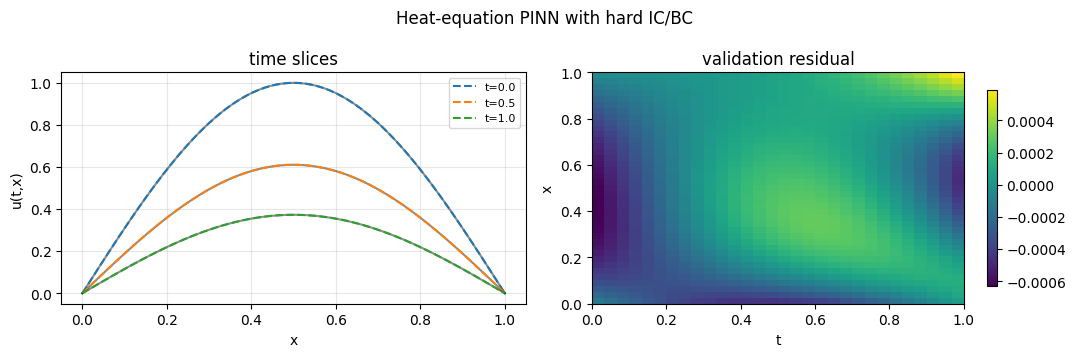

In [8]:
# Small shape checks for the hard ansatz functions.
_test_ode_hard_params = init_tanh_mlp(random.PRNGKey(2), 1, (8,))
assert jnp.ndim(hard_ode_ansatz(_test_ode_hard_params, jnp.array([0.3]))) == 0
_test_poisson_hard_params = init_tanh_mlp(random.PRNGKey(3), 2, (8,))
assert jnp.ndim(hard_poisson_2d_ansatz(_test_poisson_hard_params, jnp.array([0.3, 0.4]))) == 0
_test_heat_hard_params = init_tanh_mlp(random.PRNGKey(4), 2, (8,))
assert jnp.ndim(hard_heat_ansatz(_test_heat_hard_params, jnp.array([0.2, 0.5]))) == 0

ode_hard_config = {
    "name": "ODE hard IC",
    "seed": 10,
    "hidden_layers": (24, 24),
    "num_collocation": 33,
    "steps": 650,
    "learning_rate": 1.0e-3,
    "kappa": 4.0,
}
ode_hard_result = run_ode_hard_experiment(ode_hard_config, ode_residual, hard_ode_ansatz)
matched_soft_ode_result = next(result for result in ode_sweep_results if result["name"] == "wIC=10, lr=1e-3")
print_result_table([matched_soft_ode_result, ode_hard_result], title="Matched soft versus hard ODE condition enforcement")
plot_ode_fit_and_residual(ode_hard_result, ode_residual, hard_ode_ansatz, title="Hard-constrained ODE PINN")

poisson_hard_config = {
    "name": "2D Poisson hard BC",
    "seed": 21,
    "hidden_layers": (32, 32),
    "num_interior_axis": 9,
    "steps": 1500,
    "learning_rate": 1.0e-3,
}
poisson_hard_result = run_poisson_hard_experiment(poisson_hard_config, poisson_2d_residual, hard_poisson_2d_ansatz)
print_result_table([poisson_soft_result, poisson_ritz_result, poisson_hard_result], title="Poisson soft, Deep Ritz, and hard BCs")
plot_poisson_fields(poisson_hard_result, poisson_2d_residual, hard_poisson_2d_ansatz, title="2D Poisson PINN with hard BCs")

heat_hard_config = {
    "name": "heat hard IC/BC",
    "seed": 22,
    "hidden_layers": (24, 24),
    "num_t_axis": 7,
    "num_x_axis": 9,
    "num_ic": 21,
    "num_bc": 15,
    "steps": 650,
    "learning_rate": 1.0e-3,
    "nu": 0.1,
}
heat_hard_trial = lambda params, point: hard_heat_ansatz(params, point, nu=heat_hard_config["nu"])
heat_hard_result = run_heat_hard_experiment(heat_hard_config, heat_equation_residual, heat_hard_trial)
print_result_table([heat_soft_result, heat_hard_result], title="Soft versus hard heat-equation conditions")
plot_heat_slices(heat_hard_result, heat_equation_residual, heat_hard_trial, title="Heat-equation PINN with hard IC/BC")


> #### Further testing
>
> If time permits, change one matched soft/hard setting and compare only the condition error and residual.
>
> #### Open questions
>
> 1. Which condition errors are driven nearly to zero by construction?
> 2. Does hard enforcement also improve the validation solution error?
> 3. Where does the hard ansatz seem to change the optimization problem?


## Optional Extension: Residual Validation Away From Training Points

A small residual at collocation points is not the same as a small residual everywhere. This is why the tables above include validation residuals on separate grids.

> #### Instructions
>
> Reuse the trained soft and hard ODE models and compare their residuals on a denser validation grid.

> #### Open questions
>
> 1. Do the residual curves show structure between collocation points?
> 2. Which diagnostic would you trust most when selecting between two trained PINNs?


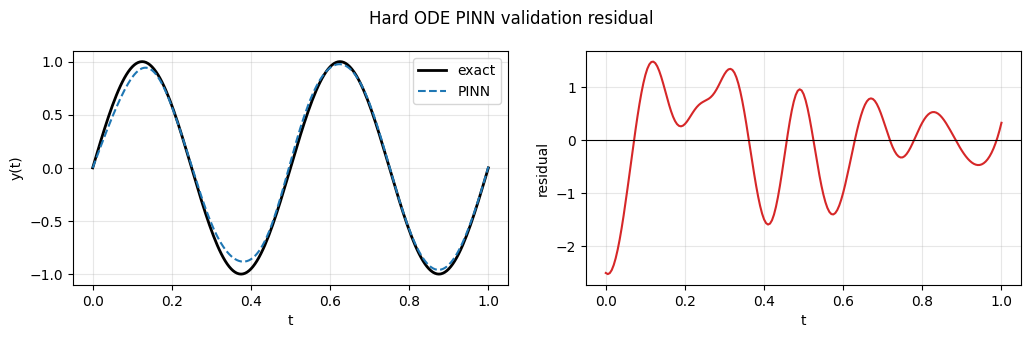

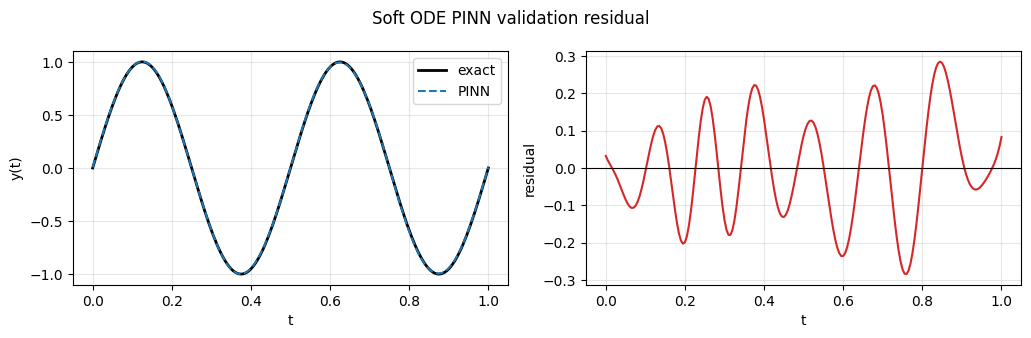

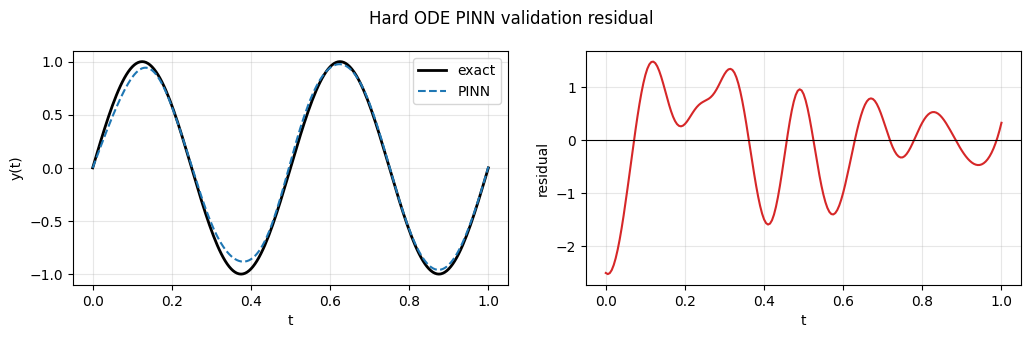

: 

In [ ]:
plot_ode_fit_and_residual(best_ode_result, ode_residual, ode_soft_trial, title="Soft ODE PINN validation residual")
plot_ode_fit_and_residual(ode_hard_result, ode_residual, hard_ode_ansatz, title="Hard ODE PINN validation residual")

> #### Further testing
>
> Compare the validation residual plot with the training-collocation diagnostics from Exercise 1.
>
> #### Open questions
>
> 1. Do the residuals stay small between the training points?
> 2. Which diagnostic would you trust most before increasing the training budget?


## Reflection and Deliverable

> #### Open questions
>
> 1. In which example did the PINN behave most like a standard supervised-learning model, and in which example did the residual diagnostics matter most?
> 2. What is the clearest tradeoff you observed between strong-form residual training, Deep Ritz training, and hard condition enforcement?
> 3. For a follow-up experiment, would you change the architecture, collocation points, loss weights, or optimizer settings first? Why?


> #### Development note
>
> Codex, a generative AI tool, was used to help generate and refine this notebook.
